In [50]:
import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [7]:
N_PORTFOLIOS = 10 ** 5
N_DAYS = 252
ASSETS = ["RBC", "TD", "BMO", "CM", "BNS"]
ASSETS.sort()

n_assets= len(ASSETS)

In [19]:
#download stock prices
prices_df = yf.download(ASSETS,
                        start= "2021-01-01",
                        end= "2021-12-31",
                        auto_adjust = True)

[*********************100%***********************]  5 of 5 completed


In [17]:
#calculate annualized average returns and corresponding standard deviation
returns_df = prices_df["Close"].pct_change().dropna()
avg_returns = returns_df.mean() * N_DAYS
cov_mat = returns_df.cov() * N_DAYS

In [18]:
# calculate portfolio weights
np.random.seed(42)
weights = np.random.random(size =(N_PORTFOLIOS, n_assets))
weights /= np.sum(weights, axis = 1)[:, np.newaxis]


In [24]:
#calculate portfolio returns, volatilities and sharpe ratios

portf_returns = np.dot(weights, avg_returns)

portf_vol = []
for i in range(0, len(weights)):
  vol = np.sqrt(
      np.dot(weights[i].T, np.dot(cov_mat, weights[i]))
  )
  portf_vol.append(vol)

portf_vol = np.array(portf_vol)
portf_sharpe_ratio = portf_returns / portf_vol

In [27]:
portf_results_df = pd.DataFrame(
    {"returns": portf_returns,
    "volatility": portf_vol,
    "sharpe_ratio": portf_sharpe_ratio}
)


In [28]:
portf_results_df.head()


,returns,volatility,sharpe_ratio
0,0.344770,0.170312,2.024348
1,0.339438,0.174641,1.943627
2,0.349301,0.153871,2.270085
3,0.340839,0.174736,1.950595
4,0.357949,0.173521,2.062860


In [35]:
#locate the points in the efficient frontier
N_POINTS = 100
ef_return_list = []
ef_vol_list = []

possible_ef_returns = np.linspace(portf_results_df["returns"].min(),
                                  portf_results_df["returns"].max(),
                                  N_POINTS)
possible_ef_returns = np.round(possible_ef_returns, 2)
portf_rts = np.round(portf_returns, 2)

In [38]:
for returns in possible_ef_returns:
  if returns in portf_rts:
    ef_return_list.append(returns)
    matched_ind = np.where(portf_rts == returns)[0]
    ef_vol_list.append(np.min(portf_vol[matched_ind]))

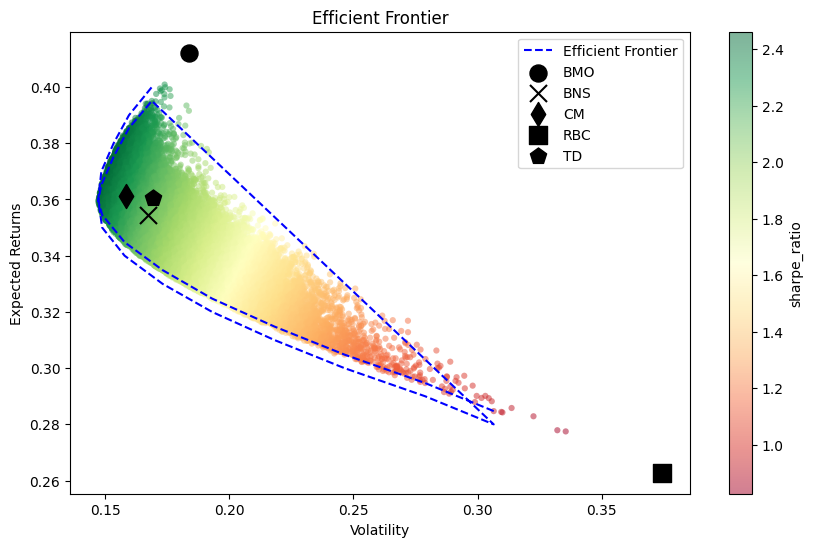

In [40]:
MARKERS = ["o", "x", "d", "s", "p"]
fig, ax = plt.subplots(figsize=(10, 6))
portf_results_df.plot(kind="scatter", x="volatility",
                      y="returns", c="sharpe_ratio",
                      cmap="RdYlGn", edgecolors="none",
                      alpha=0.5, ax=ax)

ax.set(xlabel="Volatility",
       ylabel="Expected Returns",
       title="Efficient Frontier")

ax.plot(ef_vol_list, ef_return_list, "b--", label="Efficient Frontier")

for asset_index in range(n_assets):
    ax.scatter(x=np.sqrt(cov_mat.iloc[asset_index, asset_index]),
               y=avg_returns.iloc[asset_index],
               marker=MARKERS[asset_index],
               s=150, color="black",
               label=ASSETS[asset_index])

ax.legend()
plt.show()

In [ ]:
#anything left on frontier line is not achievaable - cannot get the level of expected return for such as reutnr of volatility

In [44]:
#which one has the highest sharpe ratio
max_sharpe_ind = np.argmax(portf_results_df["sharpe_ratio"])
max_sharpe_portf = portf_results_df.iloc[max_sharpe_ind]

min_vol_ind = np.argmin(portf_results_df["volatility"])
min_vol_portf = portf_results_df.iloc[min_vol_ind]

In [46]:
# Calculate and print annualized returns and volatility for all individual stocks
individual_stats = pd.DataFrame({
    'Annualized Return': avg_returns,
    'Annualized Volatility': np.sqrt(np.diag(cov_mat))
}, index=ASSETS)

print("--- Individual Asset Performance (2021) ---")
print(individual_stats)
print("\n--- Max Sharpe Portfolio ---")
print(max_sharpe_portf)
print("\n--- Min Volatility Portfolio ---")
print(min_vol_portf)

--- Individual Asset Performance (2021) ---
     Annualized Return  Annualized Volatility
BMO           0.412215               0.183787
BNS           0.354508               0.167475
CM            0.361301               0.158241
RBC           0.262804               0.374229
TD            0.360482               0.169336

--- Max Sharpe Portfolio ---
returns         0.367847
volatility      0.149385
sharpe_ratio    2.462413
Name: 8722, dtype: float64

--- Min Volatility Portfolio ---
returns         0.359636
volatility      0.147224
sharpe_ratio    2.442788
Name: 24525, dtype: float64


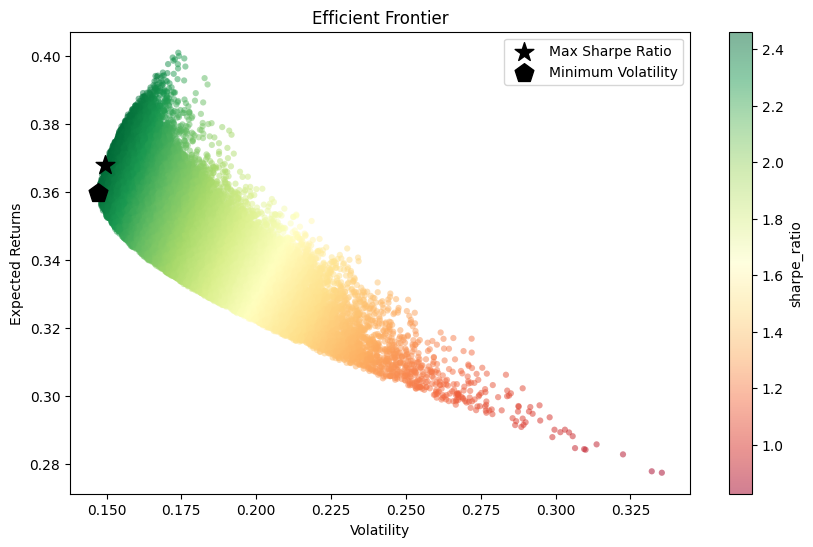

In [49]:
fig, ax  = plt.subplots(figsize=(10, 6))
portf_results_df.plot(kind= "scatter", x = "volatility",
                      y= "returns", c= "sharpe_ratio",
                      cmap = "RdYlGn", edgecolors =  "none",
                      alpha=0.5, ax= ax)

ax.scatter(x= max_sharpe_portf["volatility"],
           y = max_sharpe_portf["returns"],
           c="black", marker = "*",
           s= 200, label = "Max Sharpe Ratio")
ax.scatter(x = min_vol_portf["volatility"],
           y= min_vol_portf["returns"],
           c = "black", marker= "p",
           s= 200, label = "Minimum Volatility")
ax.set(xlabel = "Volatility", ylabel= "Expected Returns",
       title = "Efficient Frontier")

ax.legend()
plt.show()